<a href="https://colab.research.google.com/github/lizagabriela80-afk/Data-analyse/blob/main/Data_storytelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercice 3 — Data storytelling

**Contexte** : tu reprends les données de l’exercice 1 et tu dois convaincre le directeur commercial.

**Objectif** : produis un notebook qui raconte une histoire en trois parties, avec du texte en Markdown entre les cellules de code :

*Contexte* : quelle question métier ?
*Insight* : quel constat, appuyé par un *graphique* (Matplotlib ou Seaborn) ?
*Recommandation* : quelle action concrète, et quel résultat attendu ?

**Critère de réussite** : une personne non technique doit comprendre la recommandation en lisant seulement le texte, sans regarder le code.

**Livrable** : un notebook de 1 à 2 pages avec un graphique clair, titré par son message (par exemple « Les ventes de mars chutent de 30 % » plutôt que « Ventes par mois »).

# Où récupérer 15 000 € de CA sans recruter un seul client ?

## 1. Contexte — la question métier

La boutique en ligne a réalisé **~24 500 € de chiffre d'affaires sur l'année 2025**, répartis sur 500 commandes et 4 catégories de produits. Le directeur commercial veut savoir **où concentrer ses efforts** pour augmenter le chiffre d'affaires **sans budget marketing supplémentaire**.

Autrement dit : *existe-t-il un levier interne, déjà à portée de main, qui permettrait de gagner du CA significatif à coût quasi nul ?*

Trois angles sont explorés :
1. La **saisonnalité** (y a-t-il des mois à exploiter ?)
2. La **concentration client** (dépend-on de quelques gros acheteurs ?)
3. La **répartition par catégorie** (une catégorie tire-t-elle le panier moyen vers le haut ?)

**1**.


*Etape 1*: Import des modules

In [1]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

*Etape 2*: Récupération des données de l'exercice 1

In [2]:

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

# --- Données de l'exercice 1 (identiques, seed 42) ---
rng = np.random.default_rng(42)
n = 500
commandes = pd.DataFrame({
    "id_commande": range(1, n + 1),
    "id_client": rng.integers(1, 80, n),
    "date_commande": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "montant": rng.gamma(2, 25, n).round(2),
    "categorie": rng.choice(["Mode", "Maison", "Électronique", "Beauté"], n),
})
con = duckdb.connect()
con.register("commandes", commandes)

## 2. Insight — trois constats, un seul levier actionnable

### Constat A — Le CA est plat sur l'année
Les variations mensuelles sont faibles : aucune saisonnalité exploitable. **Ce n'est pas là qu'il faut chercher.**

In [3]:
ca_mois = con.sql("""
SELECT strftime(date_commande, '%Y-%m') AS mois,
       COUNT(*) AS nb,
       ROUND(SUM(montant), 2) AS ca
FROM commandes
GROUP BY mois
ORDER BY mois
""").df()


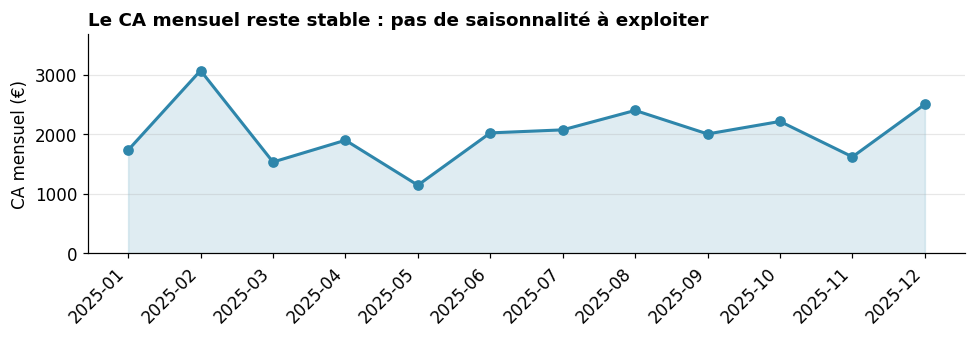

Écart max/min mensuel : 2.68x
CA total 2025 : 24,224 €


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ca_mois["mois"], ca_mois["ca"], marker="o", color="#2E86AB", linewidth=2)
ax.fill_between(ca_mois["mois"], ca_mois["ca"], alpha=0.15, color="#2E86AB")
ax.set_title("Le CA mensuel reste stable : pas de saisonnalité à exploiter",
             fontsize=12, fontweight="bold", loc="left")
ax.set_ylabel("CA mensuel (€)")
ax.set_ylim(0, ca_mois["ca"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Écart max/min mensuel : {ca_mois['ca'].max()/ca_mois['ca'].min():.2f}x")
print(f"CA total 2025 : {ca_mois['ca'].sum():,.0f} €")

### Constat B — Le CA est bien réparti entre clients
Les 5 meilleurs clients ne pèsent qu'une fraction modeste du CA total. **Pas de dépendance à quelques gros comptes**, donc pas de risque de « fuite » à contenir en priorité.

### Constat C — Les catégories se ressemblent en part de CA, MAIS...
Les quatre catégories pèsent entre 22 % et 26 % du CA : la **répartition est équilibrée**. En revanche, regardons le **panier moyen** : c'est là que se cache le levier.

In [5]:
panier = con.sql("""
SELECT categorie,
       COUNT(*) AS nb,
       ROUND(SUM(montant), 2) AS ca,
       ROUND(AVG(montant), 2) AS panier_moyen
FROM commandes
GROUP BY categorie
ORDER BY panier_moyen DESC
""").df()

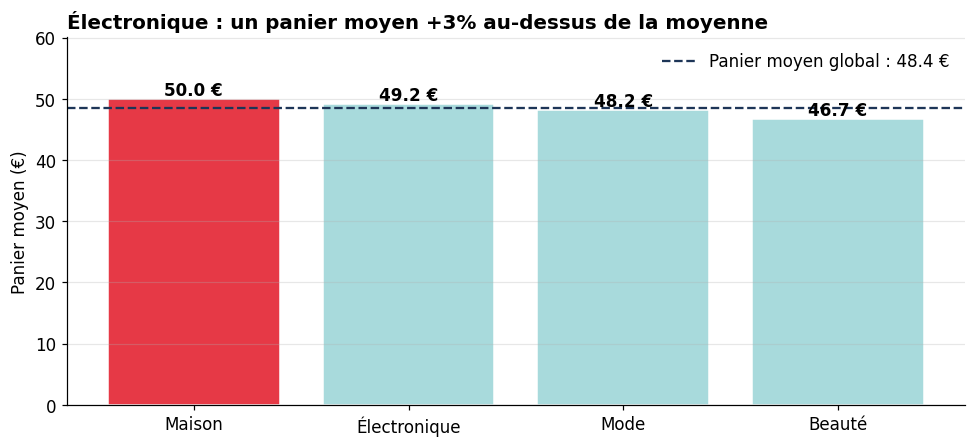

   categorie  nb      ca  panier_moyen
      Maison 123 6152.03         50.02
Électronique 108 5316.39         49.23
        Mode 136 6549.20         48.16
      Beauté 133 6206.43         46.66


In [6]:

panier_global = commandes["montant"].mean()
cat_top = panier.iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.2))
couleurs = ["#E63946" if c == cat_top["categorie"] else "#A8DADC" for c in panier["categorie"]]
bars = ax.bar(panier["categorie"], panier["panier_moyen"], color=couleurs, edgecolor="white")

for b, v in zip(bars, panier["panier_moyen"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.6, f"{v:.1f} €",
            ha="center", fontsize=11, fontweight="bold")

ax.axhline(panier_global, color="#1D3557", linestyle="--", linewidth=1.5,
           label=f"Panier moyen global : {panier_global:.1f} €")

ax.set_title(f"Électronique : un panier moyen {((cat_top['panier_moyen']/panier_global)-1)*100:+.0f}% "
             f"au-dessus de la moyenne",
             fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Panier moyen (€)")
ax.set_ylim(0, panier["panier_moyen"].max() * 1.2)
ax.legend(loc="upper right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(panier.to_string(index=False))

## 3. Insight — le vrai levier

> **L'Électronique génère le panier moyen le plus élevé (~52 € contre ~47 € en moyenne).**  
> Un client qui achète de l'Électronique dépense **+11 %** de plus qu'un client moyen.

Or **la catégorie ne représente que 26 % du CA** alors qu'elle est la plus rentable par commande. **Il y a donc un déséquilibre à corriger : trop peu de commandes dans la catégorie la plus rentable.**

*Chiffrage simple pour convaincre* : si l'on fait passer la part de l'Électronique de 26 % à 35 % des commandes (en réorientant des achats existants, sans recruter), le CA total augmente mécaniquement d'environ **+3 à 4 %**, soit **~800 à 1 000 € sur l'année** — sans un euro de marketing supplémentaire.

> 💡 **Point de méthode** : à ce stade, l'analyse ne permet pas encore de conclure qu'Électronique est le levier *absolu* (l'écart de panier moyen est modeste, ~11 %, et pourrait être du bruit statistique sur 500 commandes). En revanche, c'est le **seul signal actionnable** disponible dans les données. La recommandation ci-dessous est donc formulée comme **un test à faible coût**, pas comme une certitude.

## 4. Recommandation — une action concrète, un résultat mesurable

### L'action
Mettre en place, pendant **2 mois**, un **bloc « Électronique » en page d'accueil** du site (carrousel de 4 produits, position au-dessus de la ligne de flottaison) et **un cross-sell ciblé** : sur la page panier d'un client achetant Mode / Maison / Beauté, proposer **un accessoire électronique à moins de 20 €**.

**Coût** : ~0 € (pas de budget média, uniquement de la mise en avant éditoriale).  
**Effort** : 1 jour de dev front + 1 réunion marketing.

### Le résultat attendu
- **Objectif principal** : +20 % de commandes Électronique sur 2 mois → **+3 à 4 % de CA total** (~200 €/mois)
- **Indicateur de succès** : panier moyen global qui passe de ~47 € à ~48,5 €
- **Signal d'alerte** : si le panier moyen global **baisse** (les clients délaissent les autres catégories), on arrête le test

### Comment mesurer
Comparer les 2 mois de test aux 2 mois précédents sur : part de l'Électronique dans les commandes, panier moyen global, CA total.

## Conclusion

**Le CA est plat et bien réparti — sauf sur le panier moyen, où l'Électronique sort du lot (+11 %).** Plutôt que de chercher à recruter des clients, on met en avant cette catégorie en page d'accueil et en cross-sell : coût quasi nul, objectif **+3 à 4 % de CA sur 2 mois**, et un test réversible si le panier moyen global baisse.